# Benchmark integrado: CNNs, Kraken2 e BLASTN sob ruído

Execute no diretório do projeto que contém `utils.models` e `utils.dna_dataset_2`, usando o kernel `rapids-new`. O padrão reutiliza `benchmark_kraken_blast_v1`: mesmos FASTAs, verdade, referências e auditoria existentes. Resultados e gráficos novos ficam em `comparison_results`.

**Importante:** 95,89% de overlap foi observado no seu conjunto anterior. Avaliamos todos os métodos nos mesmos IDs, separando `all`, `overlap` e `no_exact_overlap`. Este último não comprova independência por genoma nem ausência de similaridade parcial. Bases inválidas e padding são tratados conforme o notebook de preparação. Não remova referências só de BLAST/Kraken: as CNNs já foram treinadas nelas.

In [17]:
%pip install pyarrow numpy pandas tqdm scikit-learn matplotlib seaborn
# Torch e seus módulos utils devem estar disponíveis no ambiente do treinamento.

Note: you may need to restart the kernel to use updated packages.


## Instalação dos executáveis (se necessário)
Execute no terminal do ambiente: `conda install -c conda-forge -c bioconda kraken2 blast`.

In [18]:
import shutil, subprocess, sys
from pathlib import Path
import csv, json, hashlib, os, re, time, sqlite3
from contextlib import ExitStack
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from tqdm.auto import tqdm

TRAIN = Path("processed_kraken_species_splited_parquet/train")
TEST = Path("processed_kraken_species_splited_parquet/test")
OUT = Path("benchmark_kraken_blast_20_per_species")
SEQ_COL, LABEL_COL = "sequence_padded", "label"
NUM_CLASSES = 13683
BATCH_ROWS = 8192
THREADS = min(16, os.cpu_count() or 1)
SEED = 42
NOISE_LEVELS = [0.0, 0.02, 0.05, 0.10, 0.15]
# Amostra determinística e balanceada. None = teste completo.
TEST_PER_CLASS = 20
# 'substitution': toda posição selecionada troca de base.
# 'legacy_replacement': pode repetir a base; taxa efetiva esperada = 0.75 * taxa nominal.
NOISE_MODE = "substitution"
# None = só exportar. SQLite audita duplicatas exatas e reverse complements,
# comparando todas as queries selecionadas com o treino, sem removê-las.
AUDIT_OVERLAP = True
BLAST_MAX_TARGETS = 100  # hits de referências, NÃO 100 espécies diferentes
RUN_BUILD = True       # mude para True após exportar e conferir
RUN_CLASSIFY = True

assert NOISE_MODE in {"substitution", "legacy_replacement"}
assert TEST_PER_CLASS is None or TEST_PER_CLASS > 0
OUT.mkdir(parents=True, exist_ok=True)
KDB = OUT / "kraken_db"
BDB = OUT / "blast_db" / "train"
REF_BLAST = OUT / "train_blast.fasta"
REF_KRAKEN = OUT / "train_kraken.fasta"
# True: reutiliza queries, referência e overlap existentes.
REUSE_PREPARED = False
REUSE_TOOL_OUTPUTS = False
RESULTS = OUT / "comparison_results"
RESULTS.mkdir(parents=True, exist_ok=True)
# Corrige PATH de kernels Conda iniciados pelo Jupyter.
os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ.get("PATH", "")
QUERY_PATHS = {r:OUT / f"test_noise_{round(r*100):02d}.fasta" for r in NOISE_LEVELS}
truth_path = OUT / "queries_truth.csv"
print("Python:",sys.executable, "\nDados:",OUT.resolve())

Python: /home/mlima/workspace/envs/rapids-new/bin/python 
Dados: /home/mlima/workspace/cnn_kraken/benchmark_kraken_blast_20_per_species


## Preparação opcional dos dados
Com `REUSE_PREPARED=True`, estas células preservam os dados já exportados. Para um novo benchmark, escolha um OUT novo e use False.

In [19]:
def parquet_files(path):
    files = sorted(path.rglob("*.parquet")) if path.is_dir() else [path]
    if not files or any(not f.exists() for f in files):
        raise FileNotFoundError(path)
    return files

def iter_rows(path, split):
    discarded = 0
    log = (OUT / f"discarded_{split}.csv").open("w", newline="")
    writer = csv.writer(log)
    writer.writerow(["query_id","file","row","label","reason"])
    for fi, file in enumerate(parquet_files(path)):
        pf = pq.ParquetFile(file)
        if not {SEQ_COL, LABEL_COL}.issubset(pf.schema_arrow.names):
            raise ValueError(f"Colunas ausentes: {file}: {pf.schema_arrow.names}")
        row = 0
        for batch in pf.iter_batches(batch_size=BATCH_ROWS, columns=[SEQ_COL, LABEL_COL]):
            data = batch.to_pydict()
            for seq, label in zip(data[SEQ_COL], data[LABEL_COL]):
                if label is None or int(label) != label or not 0 <= int(label) < NUM_CLASSES:
                    raise ValueError(f"Label inválido em {file}, linha {row}: {label}")
                qid = f"{split}_f{fi:05d}_r{row:010d}"
                cleaned = clean_seq(seq)
                if cleaned is None:
                    writer.writerow([qid,str(file),row,int(label),"no_acgt_bases"])
                    discarded += 1
                else:
                    yield qid, cleaned, int(label)
                row += 1

    log.close()
    print(split, "descartadas:", discarded)

def clean_seq(value):
    if not isinstance(value, str):
        raise ValueError("Sequência ausente ou não textual")
    seq = value.upper().rstrip("_").replace("_", "N")
    if not seq or not any(b in "ACGT" for b in seq):
        return None
    if re.fullmatch("[ACGTN]+", seq) is None:
        raise ValueError(f"Sequência inválida: {seq[:60]!r}")
    if len(seq) > 512:
        raise ValueError("Sequência >512; confira a coluna selecionada")
    return seq

def digest(seq):
    rc = seq.translate(str.maketrans("ACGTN", "TGCAN"))[::-1]
    return hashlib.sha256(min(seq, rc).encode()).hexdigest()

def dump_fields(fields):
    return "\t|\t".join(map(str, fields)) + "\t|\n"

In [20]:
if not REUSE_PREPARED:
    import heapq
    # Reservoir por prioridade hash; memória O(K * classes).
    def select_test():
        if TEST_PER_CLASS is None:
            yield from iter_rows(TEST, "test")
            return
        heaps = {}
        for qid, seq, label in tqdm(iter_rows(TEST, "test"), desc="Selecionando teste"):
            priority = int.from_bytes(hashlib.sha256(f"{SEED}:{qid}".encode()).digest()[:8], "big")
            item = (-priority, qid, seq, label)
            heap = heaps.setdefault(label, [])
            if len(heap) < TEST_PER_CLASS:
                heapq.heappush(heap, item)
            elif item > heap[0]:
                heapq.heapreplace(heap, item)
        for label in sorted(heaps):
            for _, qid, seq, label in sorted(heaps[label], key=lambda x:x[1]):
                yield qid, seq, label

    BASES = np.array(list("ACGT"))
    def noisy_sequence(seq, rate, qid):
        seed = int.from_bytes(hashlib.sha256(f"{SEED}:{qid}".encode()).digest()[:8], "big")
        rng = np.random.default_rng(seed)
        chars = np.array(list(seq))
        # Mesma máscara latente entre níveis: corrupção progressiva e reproduzível.
        mask = (rng.random(len(chars)) < rate) & np.isin(chars, BASES)
        if NOISE_MODE == "substitution":
            shifts = rng.integers(1, 4, size=len(chars))
            indices = np.zeros(len(chars), dtype=int)
            for i, b in enumerate(BASES):
                indices[chars == b] = i
            replacements = BASES[(indices + shifts) % 4]
        else:
            replacements = BASES[rng.integers(0, 4, size=len(chars))]
        mutated = chars.copy()
        mutated[mask] = replacements[mask]
        return "".join(mutated), int(np.count_nonzero(mutated != chars))

    QUERY_PATHS = {r: OUT / f"test_noise_{round(r*100):02d}.fasta" for r in NOISE_LEVELS}
    truth_path = OUT / "queries_truth.csv"
    if truth_path.exists():
        raise FileExistsError("Escolha outro OUT para evitar misturar execuções.")
    with ExitStack() as stack:
        handles = {r: stack.enter_context(p.open("w")) for r,p in QUERY_PATHS.items()}
        truth = csv.writer(stack.enter_context(truth_path.open("w", newline="")))
        truth.writerow(["query_id", "label", "custom_taxid", "length", "canonical_sha256"])
        audit = csv.writer(stack.enter_context((OUT / "noise_stats.csv").open("w", newline="")))
        audit.writerow(["query_id", "nominal_noise", "changed_bases", "acgt_bases"])
        for qid, seq, label in tqdm(select_test(), desc="Exportando queries"):
            truth.writerow([qid, label, label+2, len(seq), digest(seq)])
            for rate, handle in handles.items():
                noisy, changed = noisy_sequence(seq, rate, qid)
                handle.write(f">{qid}\n{noisy}\n")
                audit.writerow([qid, rate, changed, sum(b in "ACGT" for b in seq)])
    truth = pd.read_csv(truth_path)
    print("Queries:", len(truth), "classes:", truth.label.nunique())
    assert len(truth) > 0 and truth.query_id.is_unique
else:
    truth = pd.read_csv(truth_path)
    required = [*QUERY_PATHS.values(), OUT/"exact_overlap.csv"]
    missing = [str(p) for p in required if not p.exists()]
    if missing:
        raise FileNotFoundError(missing)
    assert truth.query_id.is_unique and len(truth)>0
    print("Reutilizando",len(truth),"queries")

Exportando queries: 0it [00:00, ?it/s]

Selecionando teste: 0it [00:00, ?it/s]

test descartadas: 39
Queries: 273660 classes: 13683


In [21]:
if not REUSE_PREPARED:
    overlap_db = None
    if AUDIT_OVERLAP:
        overlap_db = sqlite3.connect(OUT / "overlap.sqlite")
        overlap_db.execute("CREATE TABLE queries (hash TEXT PRIMARY KEY, train_count INTEGER DEFAULT 0)")
        overlap_db.executemany("INSERT OR IGNORE INTO queries(hash) VALUES (?)", ((x,) for x in truth.canonical_sha256))
        overlap_db.commit()
    counts = np.zeros(NUM_CLASSES, dtype=np.int64)
    with REF_BLAST.open("w") as blast, REF_KRAKEN.open("w") as kraken:
        for row_number, (rid, seq, label) in enumerate(tqdm(iter_rows(TRAIN, "train"), desc="Exportando treino"), start=1):
            # BLAST: label embutido no ID; dispensa taxonomia NCBI.
            blast.write(f">{rid}_label_{label}\n{seq}\n")
            kraken.write(f">{rid}|kraken:taxid|{label+2}\n{seq}\n")
            counts[label] += 1
            if overlap_db is not None:
                overlap_db.execute("UPDATE queries SET train_count=train_count+1 WHERE hash=?", (digest(seq),))
                if row_number % 100000 == 0:
                    overlap_db.commit()
    if overlap_db is not None:
        overlap_db.commit()
        matches = pd.read_sql_query("SELECT hash, train_count FROM queries", overlap_db)
        overlap_db.close()
        overlap = truth.merge(matches, left_on="canonical_sha256", right_on="hash", how="left")
        overlap.to_csv(OUT / "exact_overlap.csv", index=False)
        print("Queries idênticas ao treino (inclui reverse complement):", int((overlap.train_count > 0).sum()))
        # Não remover silenciosamente: avaliar estratos com/sem sobreposição,
        # ou definir um novo protocolo e reavaliar TODOS os métodos.
    pd.DataFrame({"label": np.arange(NUM_CLASSES), "train_count":counts}).to_csv(OUT / "train_counts.csv", index=False)
    assert np.all(counts > 0), "Há classes ausentes do treino; revise NUM_CLASSES e labels."

Exportando treino: 0it [00:00, ?it/s]

train descartadas: 334
Queries idênticas ao treino (inclui reverse complement): 262470


In [22]:
if not REUSE_PREPARED:
    taxonomy = KDB / "taxonomy"
    taxonomy.mkdir(parents=True, exist_ok=True)
    with (taxonomy / "nodes.dmp").open("w") as nodes, (taxonomy / "names.dmp").open("w") as names:
        # 13 campos NCBI; root taxid=1; classe 0 -> taxid=2.
        nodes.write(dump_fields([1,1,"no rank","",0,0,1,0,0,0,0,0,""]))
        names.write(dump_fields([1,"root","","scientific name"]))
        for label in range(NUM_CLASSES):
            tid = label+2
            nodes.write(dump_fields([tid,1,"species","",0,0,1,0,0,0,0,0,""]))
            names.write(dump_fields([tid,f"class_{label}","","scientific name"]))
    pd.DataFrame({"label":range(NUM_CLASSES), "custom_taxid":np.arange(NUM_CLASSES)+2}).to_csv(OUT / "label_taxid.csv", index=False)

## Auditoria e identificação dos três grupos

In [23]:
overlap = pd.read_csv(OUT / "exact_overlap.csv")
if not overlap.query_id.is_unique or set(overlap.query_id) != set(truth.query_id):
    raise ValueError("Auditoria e queries não correspondem")
joined = truth.merge(overlap[["query_id","label","train_count"]], on="query_id", validate="one_to_one", suffixes=("","_audit"))
assert (joined.label == joined.label_audit).all()
assert joined.train_count.notna().all() and (joined.train_count >= 0).all()
truth = joined.drop(columns="label_audit")
truth["has_overlap"] = truth.train_count.gt(0)
summary = truth.groupby("has_overlap").agg(n=("query_id","size"), classes=("label","nunique"))
summary["percent"] = 100*summary.n/len(truth)
display(summary)
summary.to_csv(RESULTS/"overlap_summary.csv")
truth.groupby("label").has_overlap.agg(["size","sum","mean"]).to_csv(RESULTS/"overlap_by_species.csv")
if (OUT/"manifest.json").exists():
    previous_manifest = json.loads((OUT/"manifest.json").read_text())
    print("Ruído dos FASTAs existentes:",previous_manifest.get("noise_mode"))
    # Verifica integridade dos FASTAs, quando hashes foram registrados.
    for rate, path in QUERY_PATHS.items():
        expected = previous_manifest.get("query_sha256",{}).get(str(path))
        if expected:
            h=hashlib.sha256()
            with path.open("rb") as f:
                for chunk in iter(lambda:f.read(8*1024*1024),b""):h.update(chunk)
            assert h.hexdigest()==expected, f"FASTA alterado: {path}"

,n,classes,percent
has_overlap,,,
False,11190,7691,4.089016
True,262470,13683,95.910984


In [24]:
def run_command(args):
    args = list(map(str, args))
    with (OUT / "commands.jsonl").open("a") as f:
        f.write(json.dumps({"args":args, "time":time.time()}) + "\n")
    print("Executando:", args)
    subprocess.run(args, check=True)  # sem shell; erros interrompem a execução

versions = {}
for executable in ("kraken2", "blastn", "makeblastdb"):
    if shutil.which(executable):
        flag = "--version" if executable == "kraken2" else "-version"
        result = subprocess.run([executable,flag], capture_output=True, text=True)
        versions[executable] = result.stdout + result.stderr
    else:
        versions[executable] = "NÃO ENCONTRADO"
(OUT / "versions.json").write_text(json.dumps(versions, indent=2))
print(versions)
BDB.parent.mkdir(parents=True, exist_ok=True)
if RUN_BUILD:
    run_command(["makeblastdb", "-in", REF_BLAST, "-dbtype", "nucl", "-parse_seqids", "-out", BDB])
    run_command(["kraken2-build", "--add-to-library", REF_KRAKEN, "--db", KDB])
    run_command(["kraken2-build", "--build", "--db", KDB, "--threads", THREADS])
else:
    print("FASTA pronto. Defina RUN_BUILD=True e reexecute esta célula para construir os bancos.")

{'kraken2': 'Kraken version 2.17.1\nCopyright 2013-2023, Derrick Wood (dwood@cs.jhu.edu)\n', 'blastn': 'blastn: 2.17.0+\n Package: blast 2.17.0, build Aug 11 2025 09:46:06\n', 'makeblastdb': 'makeblastdb: 2.17.0+\n Package: blast 2.17.0, build Aug 11 2025 09:46:06\n'}
Executando: ['makeblastdb', '-in', 'benchmark_kraken_blast_20_per_species/train_blast.fasta', '-dbtype', 'nucl', '-parse_seqids', '-out', 'benchmark_kraken_blast_20_per_species/blast_db/train']


Building a new DB, current time: 10/01/2026 12:16:50
New DB name:   /home/mlima/workspace/cnn_kraken/benchmark_kraken_blast_20_per_species/blast_db/train
New DB title:  benchmark_kraken_blast_20_per_species/train_blast.fasta
Sequence type: Nucleotide
Keep MBits: T
Maximum file size: 3000000000B
Adding sequences from FASTA; added 13649826 sequences in 177.676 seconds.


Executando: ['kraken2-build', '--add-to-library', 'benchmark_kraken_blast_20_per_species/train_kraken.fasta', '--db', 'benchmark_kraken_blast_20_per_species/kraken

Masking low-complexity regions of new file... done.
Added "benchmark_kraken_blast_20_per_species/train_kraken.fasta" to library (benchmark_kraken_blast_20_per_species/kraken_db)


Executando: ['kraken2-build', '--build', '--db', 'benchmark_kraken_blast_20_per_species/kraken_db', '--threads', '16']
Creating sequence ID to taxonomy ID map (step 1)...
Sequence ID to taxonomy ID map complete. [16.360s]
Estimating required capacity (step 2)...


Completed processing of 13649826 sequences, 4176616664 bp
Writing data to disk...  complete.


Database files completed. 24.012s]
Database construction complete. [Total: 28m47.470s]


## Kraken2 e BLASTN
Saídas antigas podem ser reutilizadas se pertencem aos mesmos FASTAs e parâmetros. Para refazer, use `REUSE_TOOL_OUTPUTS=False`. Arquivos temporários só são promovidos após o comando concluir.

In [ ]:
def run_atomic(args, final):
    tmp = Path(str(final)+".partial")
    start=time.perf_counter()
    run_command([str(tmp) if str(x)==str(final) else x for x in args])
    tmp.replace(final)
    with (RESULTS/"runtime.jsonl").open("a") as f:
        f.write(json.dumps({"output":str(final),"seconds":time.perf_counter()-start})+"\n")

if RUN_CLASSIFY:
    for rate, query in QUERY_PATHS.items():
        tag=f"noise_{round(rate*100):02d}"
        kp=OUT/f"kraken_{tag}.out"
        bp=OUT/f"blast_{tag}.tsv"
        if not(REUSE_TOOL_OUTPUTS and kp.exists()):
            for name in ("hash.k2d","opts.k2d","taxo.k2d"):
                if not (KDB/name).exists():raise FileNotFoundError(f"Construa o banco: {KDB/name}")
            run_atomic(["kraken2","--db",KDB,"--threads",THREADS,"--confidence","0.0",
                        "--output",kp,"--report",OUT/f"kraken_{tag}.report",query],kp)
        if not(REUSE_TOOL_OUTPUTS and bp.exists()):
            run_atomic(["blastn","-task","blastn","-query",query,"-db",BDB,
                        "-num_threads",THREADS,"-evalue","1e-5","-dust","yes",
                        "-max_target_seqs",BLAST_MAX_TARGETS,"-max_hsps","1",
                        "-outfmt","6 qseqid sseqid bitscore evalue pident length qcovhsp","-out",bp],bp)

Executando: ['kraken2', '--db', 'benchmark_kraken_blast_20_per_species/kraken_db', '--threads', '16', '--confidence', '0.0', '--output', 'benchmark_kraken_blast_20_per_species/kraken_noise_00.out.partial', '--report', 'benchmark_kraken_blast_20_per_species/kraken_noise_00.report', 'benchmark_kraken_blast_20_per_species/test_noise_00.fasta']


Loading database information... done.
273660 sequences (83.86 Mbp) processed in 0.644s (25480.2 Kseq/m, 7808.19 Mbp/m).
  273460 sequences classified (99.93%)
  200 sequences unclassified (0.07%)


Executando: ['blastn', '-task', 'blastn', '-query', 'benchmark_kraken_blast_20_per_species/test_noise_00.fasta', '-db', 'benchmark_kraken_blast_20_per_species/blast_db/train', '-num_threads', '16', '-evalue', '1e-5', '-dust', 'yes', '-max_target_seqs', '100', '-max_hsps', '1', '-outfmt', '6 qseqid sseqid bitscore evalue pident length qcovhsp', '-out', 'benchmark_kraken_blast_20_per_species/blast_noise_00.tsv.partial']
Executando: ['kraken2', '--db', 'benchmark_kraken_blast_20_per_species/kraken_db', '--threads', '16', '--confidence', '0.0', '--output', 'benchmark_kraken_blast_20_per_species/kraken_noise_10.out.partial', '--report', 'benchmark_kraken_blast_20_per_species/kraken_noise_10.report', 'benchmark_kraken_blast_20_per_species/test_noise_10.fasta']


Loading database information... done.
273660 sequences (83.86 Mbp) processed in 2.676s (6135.5 Kseq/m, 1880.16 Mbp/m).
  218393 sequences classified (79.80%)
  55267 sequences unclassified (20.20%)


Executando: ['blastn', '-task', 'blastn', '-query', 'benchmark_kraken_blast_20_per_species/test_noise_10.fasta', '-db', 'benchmark_kraken_blast_20_per_species/blast_db/train', '-num_threads', '16', '-evalue', '1e-5', '-dust', 'yes', '-max_target_seqs', '100', '-max_hsps', '1', '-outfmt', '6 qseqid sseqid bitscore evalue pident length qcovhsp', '-out', 'benchmark_kraken_blast_20_per_species/blast_noise_10.tsv.partial']


## CNNs: checkpoints e loader original
Usamos as arquiteturas e caminhos do `noise_compare.ipynb`. O loader original recebe Parquets temporários derivados dos mesmos FASTAs. O label nesses Parquets é a **posição da query**, para recuperar IDs mesmo se o loader alterar a ordem. O label verdadeiro vem de `queries_truth.csv`.

Nenhuma CNN é avaliada com pesos aleatórios: arquivo ausente ou incompatibilidade interrompe a execução. Torch não é reinstalado para preservar sua instalação CUDA. `weights_only=True` aceita checkpoints de tensores; se seu checkpoint contém objetos extras, converta-o em state_dict no ambiente original. N interno vira `_`, reproduzindo o token desconhecido do pré-processamento; padding é acrescentado até 512.

In [33]:
import torch
from torch.utils.data import DataLoader
from utils.models import resnet50_1d, convnext_tiny_1d
from utils.dna_dataset_2 import ParquetCPUDataset

DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
CNN_BATCH_SIZE=512
MAX_SEQUENCE_LENGTH=512
NUM_FEATURES=4
MODEL_SPECS = {
 "ResNet50":("resnet", "../cnn_kraken_species/checkpoints/best_resnet_classifier__fast_phase4.pt"),
 "ResNet_F":("resnet", "./checkpoint_finetune_resnet/finetune_noise_14.pt"),
 "ConvNeXt_Z":("convnext", "./checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt"),
 "ConvNeXt_T":("convnext", "./checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"),
 "ConvNeXt_F":("convnext", "./checkpoint_transfer_species_conv/finetune_noise_7.pt"),
}
# Edite MODEL_SPECS para escolher os modelos. Reutilização exige mesmos checkpoints.
REUSE_CNN_OUTPUTS=False
for name,(_, checkpoint) in MODEL_SPECS.items():
    if not Path(checkpoint).is_file():raise FileNotFoundError(f"{name}: {checkpoint}")
print("Device:",DEVICE)

def load_model(architecture, checkpoint):
    factory=resnet50_1d if architecture=="resnet" else convnext_tiny_1d
    model=factory(MAX_SEQUENCE_LENGTH,NUM_FEATURES,NUM_CLASSES,debug=False,dropout_rate=0.7)
    state=torch.load(checkpoint,map_location="cpu",weights_only=True)
    for key in ("model_state_dict","state_dict"):
        if isinstance(state,dict) and key in state:
            state=state[key];break
    cleaned={}
    for key,value in state.items():
        while key.startswith(("_orig_mod.","module.")):
            key=key.split(".",1)[1]
        if key in cleaned:raise ValueError(f"Chave duplicada: {key}")
        cleaned[key]=value
    model.load_state_dict(cleaned,strict=True)
    return model.to(DEVICE).eval()

def read_fasta(path):
    qid=None;parts=[]
    with path.open() as f:
        for line in f:
            line=line.strip()
            if not line:continue
            if line.startswith(">"):
                if qid is not None:yield qid,"".join(parts)
                qid=line[1:].split()[0];parts=[]
            else:
                if qid is None:raise ValueError("FASTA sem header")
                parts.append(line)
    if qid is not None:yield qid,"".join(parts)

CACHE=RESULTS/"query_parquets"
CACHE.mkdir(exist_ok=True)
query_ids=truth.query_id.tolist()
positions={q:i for i,q in enumerate(query_ids)}
for rate,path in QUERY_PATHS.items():
    records=[];seen=set()
    for qid,seq in read_fasta(path):
        if qid not in positions or qid in seen:raise ValueError(f"ID inválido/duplicado: {qid}")
        seen.add(qid)
        if not 0<len(seq)<=512 or re.fullmatch("[ACGTN]+",seq) is None:raise ValueError(qid)
        records.append({"sequence_padded":seq.replace("N","_").ljust(512,"_"),"label":positions[qid]})
    if seen!=set(query_ids):raise ValueError(f"Queries incompletas: {path}")
    pd.DataFrame(records).to_parquet(CACHE/f"noise_{round(rate*100):02d}.parquet",index=False)

Device: cuda


In [34]:
for name,(architecture,checkpoint) in MODEL_SPECS.items():
    model=load_model(architecture,checkpoint)
    for rate in NOISE_LEVELS:
        dest=RESULTS/f"predictions_{name}_noise_{round(rate*100):02d}.parquet"
        if REUSE_CNN_OUTPUTS and dest.exists():continue
        dataset=ParquetCPUDataset([str(CACHE/f"noise_{round(rate*100):02d}.parquet")],
            "sequence_padded","label",512,["A","C","G","T"],CNN_BATCH_SIZE)
        loader=DataLoader(dataset,batch_size=None,num_workers=0)
        top5=np.full((len(truth),5),-1,dtype=np.int64)
        seen=np.zeros(len(truth),dtype=bool)
        start=time.perf_counter()
        if DEVICE.type=="cuda":torch.cuda.synchronize()
        with torch.inference_mode():
            for inputs,index in tqdm(loader,desc=f"{name} {rate:.0%}"):
                idx=index.cpu().numpy().astype(np.int64)
                if len(np.unique(idx))!=len(idx) or (idx<0).any() or (idx>=len(truth)).any() or seen[idx].any():
                    raise ValueError("Loader duplicou ou alterou índices")
                logits=model(inputs.to(DEVICE))
                if logits.shape!=(len(idx),NUM_CLASSES):raise ValueError(f"Saída inesperada: {logits.shape}")
                top5[idx]=logits.topk(5,dim=1).indices.cpu().numpy()
                seen[idx]=True
        if DEVICE.type=="cuda":torch.cuda.synchronize()
        elapsed=time.perf_counter()-start
        if not seen.all():raise ValueError(f"Loader omitiu {int((~seen).sum())} queries")
        prediction=pd.DataFrame({"query_id":query_ids,"prediction":top5[:,0]})
        for k in range(5):prediction[f"top{k+1}"]=top5[:,k]
        tmp=Path(str(dest)+".partial")
        prediction.to_parquet(tmp,index=False);tmp.replace(dest)
        with (RESULTS/"runtime.jsonl").open("a") as f:
            f.write(json.dumps({"method":name,"noise":rate,"seconds":elapsed,"n":len(truth),"scope":"CNN inference plus loader; excludes checkpoint loading"})+"\n")
    del model
    if DEVICE.type=="cuda":torch.cuda.empty_cache()

ResNet50 0%:   0%|          | 0/535 [00:00<?, ?it/s]

ResNet50 2%:   0%|          | 0/535 [00:00<?, ?it/s]

ResNet50 5%:   0%|          | 0/535 [00:00<?, ?it/s]

ResNet50 10%:   0%|          | 0/535 [00:00<?, ?it/s]

ResNet50 15%:   0%|          | 0/535 [00:00<?, ?it/s]

...

ConvNeXt_F 0%:   0%|          | 0/535 [00:00<?, ?it/s]

ConvNeXt_F 2%:   0%|          | 0/535 [00:00<?, ?it/s]

ConvNeXt_F 5%:   0%|          | 0/535 [00:00<?, ?it/s]

ConvNeXt_F 10%:   0%|          | 0/535 [00:00<?, ?it/s]

ConvNeXt_F 15%:   0%|          | 0/535 [00:00<?, ?it/s]

## Converter BLAST e Kraken2 para uma saída comum
Top-5 do BLAST é limitado aos hits recuperados, colapsados por espécie. Empates: bitscore, E-value e label. Kraken2 tem apenas Top-1; raiz e unclassified recebem -1.

In [35]:
from sklearn.metrics import f1_score

def parse_kraken(path):
    predictions = {}
    with path.open() as f:
        for line in f:
            status, qid, taxid, *_ = line.rstrip().split("\t")
            tid = int(taxid)
            label = tid-2 if status == "C" and 2 <= tid < NUM_CLASSES+2 else -1
            if qid in predictions:
                raise ValueError("Query duplicada na saída Kraken")
            predictions[qid] = label
    if set(predictions) != set(truth.query_id):
        raise ValueError("Saída Kraken incompleta ou de outro conjunto de queries")
    return predictions

def parse_blast(path):
    # Streaming; O(queries * até 5 espécies), sem carregar toda a TSV.
    top = {}
    known = set(truth.query_id)
    with path.open() as f:
        for line in f:
            qid, sid, score, ev, *_ = line.rstrip().split("\t")
            if qid not in known:
                raise ValueError(f"Query desconhecida: {qid}")
            match = re.search(r"_label_(\d+)$", sid)
            if not match:
                raise ValueError(f"Subject ID inesperado: {sid}")
            label = int(match.group(1))
            candidates = top.setdefault(qid, {})
            value = (float(score), -float(ev))
            candidates[label] = max(value, candidates.get(label, (-float('inf'), -float('inf'))))
            # Regra: máximo bitscore por espécie; empates por evalue e label.
            best = sorted(candidates, key=lambda x:(-candidates[x][0], -candidates[x][1], x))[:5]
            top[qid] = {x:candidates[x] for x in best}
    return {qid:sorted(v, key=lambda x:(-v[x][0], -v[x][1], x)) for qid,v in top.items()}


for rate in NOISE_LEVELS:
    tag=f"noise_{round(rate*100):02d}"
    for method in ("Kraken2-flat","BLASTN"):
        path=OUT/f"{'kraken' if method=='Kraken2-flat' else 'blast'}_{tag}.{'out' if method=='Kraken2-flat' else 'tsv'}"
        if not path.exists():raise FileNotFoundError(path)
        parsed=parse_kraken(path) if method=="Kraken2-flat" else parse_blast(path)
        ranks=[[parsed[q]] for q in query_ids] if method=="Kraken2-flat" else [parsed.get(q,[]) for q in query_ids]
        prediction=pd.DataFrame({"query_id":query_ids,"prediction":[r[0] if r else -1 for r in ranks]})
        if method=="BLASTN":
            for k in range(5):prediction[f"top{k+1}"]=[r[k] if len(r)>k else -1 for r in ranks]
        prediction.to_parquet(RESULTS/f"predictions_{method}_{tag}.parquet",index=False)

## Métricas pareadas e estratificadas
Acurácia considera todas as queries, inclusive abstensões. Macro-F1 é calculado nas classes verdadeiras presentes em cada estrato; os estratos podem ter conjuntos distintos de classes. Reportamos `n` e `n_classes`. Intervalo de Wilson da acurácia é descritivo e trata queries como independentes; não corrige dependência entre fragmentos/genomas.

In [36]:
def wilson(successes,n,z=1.96):
    p=successes/n;den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half

rows=[]
methods=[*MODEL_SPECS,"Kraken2-flat","BLASTN"]
for method in methods:
    for rate in NOISE_LEVELS:
        path=RESULTS/f"predictions_{method}_noise_{round(rate*100):02d}.parquet"
        predictions=pd.read_parquet(path)
        if not predictions.query_id.is_unique or set(predictions.query_id)!=set(query_ids):raise ValueError(path)
        df=truth.merge(predictions,on="query_id",validate="one_to_one")
        if df.prediction.isna().any():raise ValueError("Predição ausente")
        for group,mask in [("all",np.ones(len(df),dtype=bool)),("overlap",df.has_overlap), ("no_exact_overlap",~df.has_overlap)]:
            d=df.loc[mask]
            if d.empty:continue
            y=d.label.to_numpy();p=d.prediction.to_numpy();covered=p>=0
            hit=p==y
            low,high=wilson(hit.sum(),len(d))
            topcols=[f"top{k}" for k in range(1,6)]
            top5=float((d[topcols].to_numpy()==y[:,None]).any(axis=1).mean()) if all(c in d for c in topcols) else np.nan
            rows.append(dict(method=method,noise=rate,group=group,n=len(d),n_classes=d.label.nunique(),
                accuracy=hit.mean(),accuracy_ci_low=low,accuracy_ci_high=high,coverage=covered.mean(),
                conditional_accuracy=float((p[covered]==y[covered]).mean()) if covered.any() else np.nan,
                macro_f1=f1_score(y,p,labels=np.unique(y),average="macro",zero_division=0),top5=top5))
if not rows:raise RuntimeError("Nenhuma métrica produzida")
metrics=pd.DataFrame(rows)
metrics.to_csv(RESULTS/"metrics_by_overlap.csv",index=False)
for group in metrics.group.unique():
    print("\n",group)
    display(metrics[metrics.group==group].round(4))

/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  ys_types = set(type_of_target(x) for x in ys)
/home/mlima/workspace/envs/rapids-new/lib/pyt


 all


/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  ys_types = set(type_of_target(x) for x in ys)
/home/mlima/workspace/envs/rapids-new/lib/pyt

,method,noise,group,n,n_classes,accuracy,accuracy_ci_low,accuracy_ci_high,coverage,conditional_accuracy,macro_f1,top5
0,ResNet50,0.00,all,273660,13683,0.8490,0.8477,0.8504,1.0000,0.8490,0.8454,0.9098
3,ResNet50,0.02,all,273660,13683,0.3497,0.3479,0.3515,1.0000,0.3497,0.4020,0.4613
6,ResNet50,0.05,all,273660,13683,0.0720,0.0710,0.0730,1.0000,0.0720,0.0987,0.1200
9,ResNet50,0.10,all,273660,13683,0.0082,0.0078,0.0085,1.0000,0.0082,0.0100,0.0200
12,ResNet50,0.15,all,273660,13683,0.0022,0.0020,0.0024,1.0000,0.0022,0.0022,0.0070
15,ResNet_F,0.00,all,273660,13683,0.3295,0.3277,0.3312,1.0000,0.3295,0.3335,0.4003
18,ResNet_F,0.02,all,273660,13683,0.2590,0.2574,0.2607,1.0000,0.2590,0.2663,0.3327
21,ResNet_F,0.05,all,273660,13683,0.1603,0.1589,0.1616,1.0000,0.1603,0.1685,0.2301
24,ResNet_F,0.10,all,273660,13683,0.0547,0.0538,0.0555,1.0000,0.0547,0.0562,0.1000
27,ResNet_F,0.15,all,273660,13683,0.0164,0.0160,0.0169,1.0000,0.0164,0.0143,0.0383



 overlap


,method,noise,group,n,n_classes,accuracy,accuracy_ci_low,accuracy_ci_high,coverage,conditional_accuracy,macro_f1,top5
1,ResNet50,0.00,overlap,262470,13683,0.8594,0.8580,0.8607,1.0000,0.8594,0.8555,0.9183
4,ResNet50,0.02,overlap,262470,13683,0.3523,0.3505,0.3541,1.0000,0.3523,0.4042,0.4649
7,ResNet50,0.05,overlap,262470,13683,0.0725,0.0715,0.0735,1.0000,0.0725,0.0992,0.1208
10,ResNet50,0.10,overlap,262470,13683,0.0081,0.0078,0.0085,1.0000,0.0081,0.0100,0.0200
13,ResNet50,0.15,overlap,262470,13683,0.0022,0.0020,0.0024,1.0000,0.0022,0.0023,0.0069
16,ResNet_F,0.00,overlap,262470,13683,0.3300,0.3282,0.3318,1.0000,0.3300,0.3339,0.4008
19,ResNet_F,0.02,overlap,262470,13683,0.2594,0.2578,0.2611,1.0000,0.2594,0.2668,0.3329
22,ResNet_F,0.05,overlap,262470,13683,0.1604,0.1590,0.1618,1.0000,0.1604,0.1686,0.2302
25,ResNet_F,0.10,overlap,262470,13683,0.0546,0.0538,0.0555,1.0000,0.0546,0.0561,0.0999
28,ResNet_F,0.15,overlap,262470,13683,0.0163,0.0159,0.0168,1.0000,0.0163,0.0142,0.0382



 no_exact_overlap


,method,noise,group,n,n_classes,accuracy,accuracy_ci_low,accuracy_ci_high,coverage,conditional_accuracy,macro_f1,top5
2,ResNet50,0.00,no_exact_overlap,11190,7691,0.6069,0.5978,0.6159,1.0000,0.6069,0.6004,0.7086
5,ResNet50,0.02,no_exact_overlap,11190,7691,0.2892,0.2809,0.2977,1.0000,0.2892,0.2941,0.3777
8,ResNet50,0.05,no_exact_overlap,11190,7691,0.0605,0.0562,0.0651,1.0000,0.0605,0.0615,0.1000
11,ResNet50,0.10,no_exact_overlap,11190,7691,0.0087,0.0071,0.0106,1.0000,0.0087,0.0068,0.0196
14,ResNet50,0.15,no_exact_overlap,11190,7691,0.0021,0.0014,0.0031,1.0000,0.0021,0.0012,0.0081
17,ResNet_F,0.00,no_exact_overlap,11190,7691,0.3161,0.3075,0.3248,1.0000,0.3161,0.2956,0.3885
20,ResNet_F,0.02,no_exact_overlap,11190,7691,0.2492,0.2412,0.2573,1.0000,0.2492,0.2287,0.3262
23,ResNet_F,0.05,no_exact_overlap,11190,7691,0.1568,0.1502,0.1637,1.0000,0.1568,0.1386,0.2276
26,ResNet_F,0.10,no_exact_overlap,11190,7691,0.0557,0.0516,0.0601,1.0000,0.0557,0.0451,0.1010
29,ResNet_F,0.15,no_exact_overlap,11190,7691,0.0183,0.0160,0.0210,1.0000,0.0183,0.0132,0.0425


## Gráficos de robustez e efeito do overlap

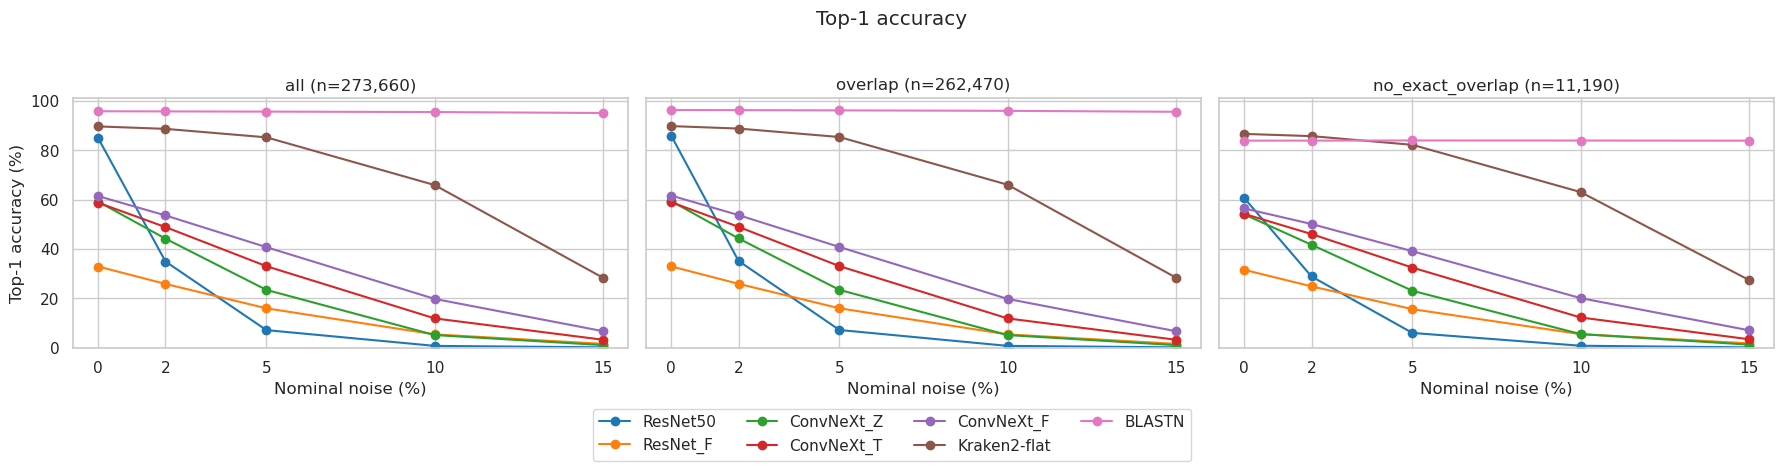

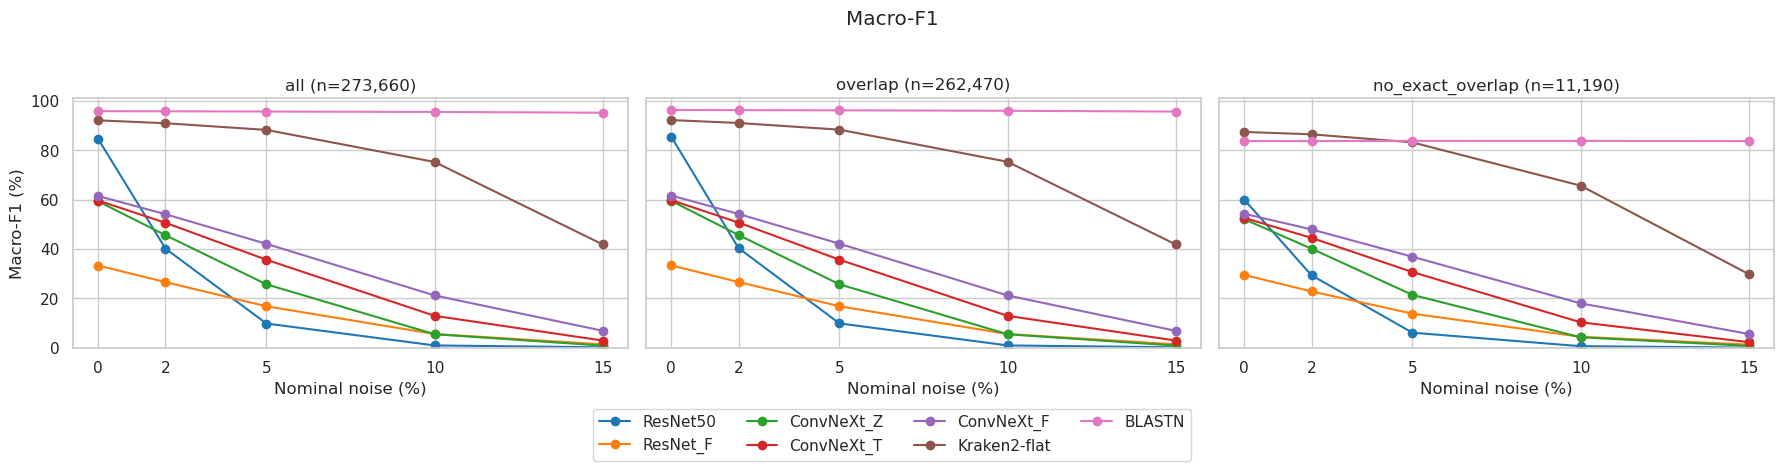

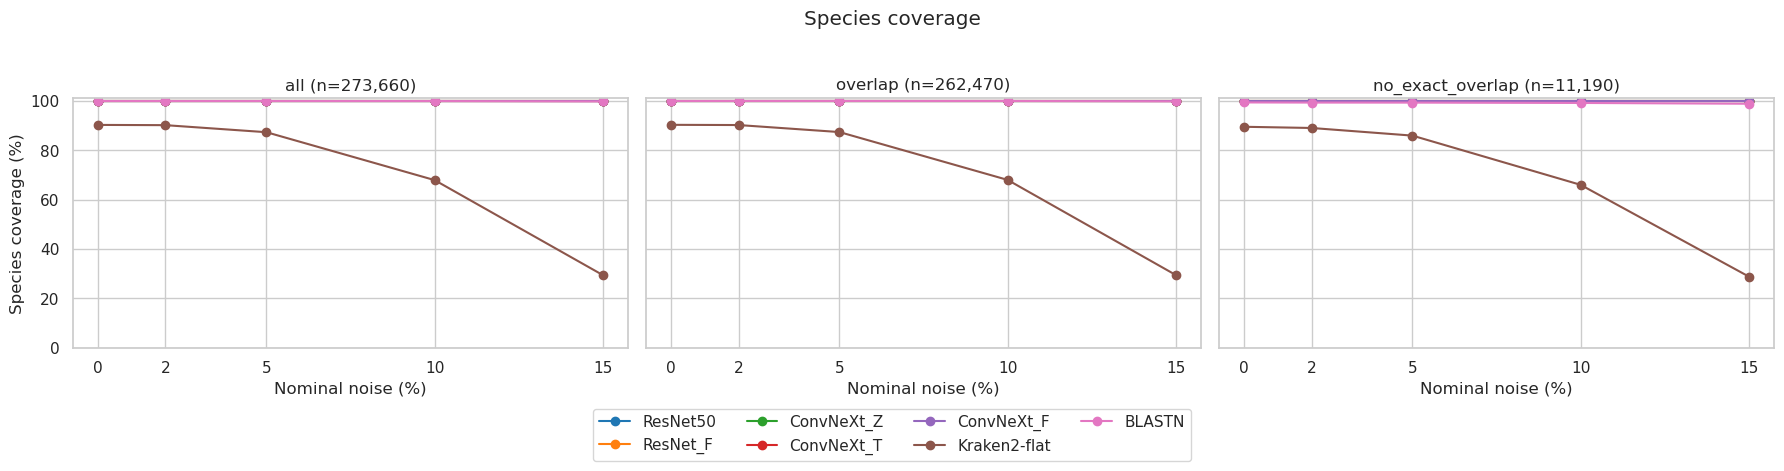

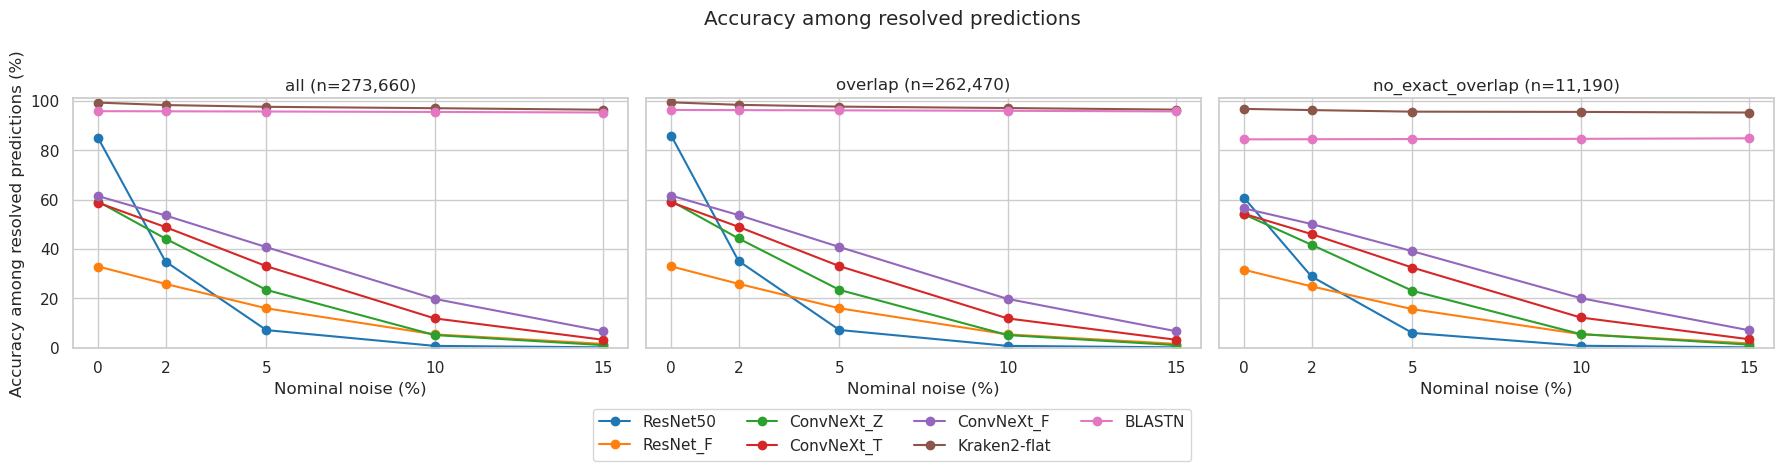

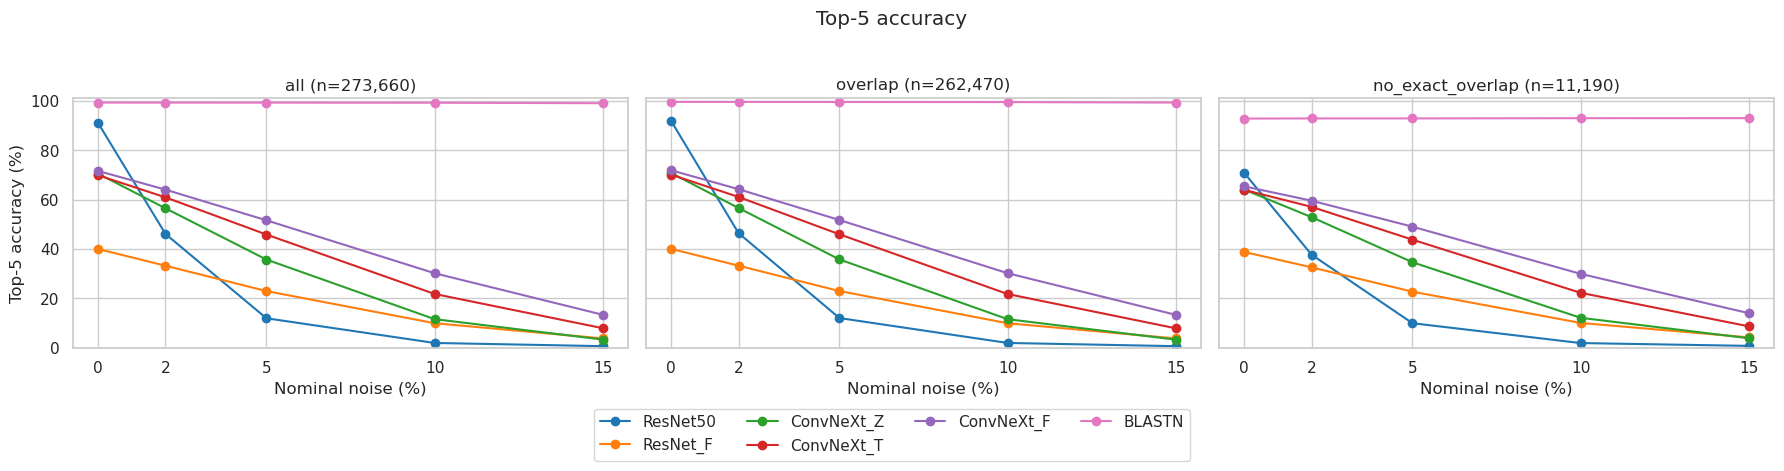

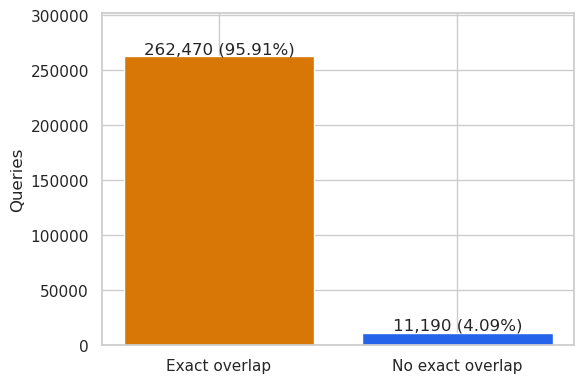

group                  all  no_exact_overlap  overlap  difference_pp
method       noise                                                  
BLASTN       0.00   0.9582            0.8392   0.9633        12.4044
             0.02   0.9577            0.8393   0.9627        12.3376
             0.05   0.9568            0.8399   0.9618        12.1963
             0.10   0.9550            0.8397   0.9599        12.0252
             0.15   0.9513            0.8391   0.9561        11.7011
ConvNeXt_F   0.00   0.6146            0.5647   0.6167         5.1979
             0.02   0.5364            0.5017   0.5378         3.6146
             0.05   0.4079            0.3915   0.4086         1.7100
             0.10   0.1985            0.2016   0.1983        -0.3281
             0.15   0.0679            0.0715   0.0677        -0.3763
ConvNeXt_T   0.00   0.5877            0.5425   0.5897         4.7129
             0.02   0.4891            0.4609   0.4903         2.9341
             0.05   0.3308            0.3251   0.3311         0.5962
             0.10   0.1195            0.1231   0.1194        -0.3787
             0.15   0.0331            0.0351   0.0330        -0.2092
ConvNeXt_Z   0.00   0.5922            0.5404   0.5944         5.4033
             0.02   0.4422            0.4176   0.4433         2.5676
             0.05   0.2348            0.2313   0.2350         0.3675
             0.10   0.0521            0.0559   0.0519        -0.3920
             0.15   0.0113            0.0131   0.0112        -0.1962
Kraken2-flat 0.00   0.8968            0.8665   0.8981         3.1645
             0.02   0.8869            0.8576   0.8882         3.0649
             0.05   0.8526            0.8223   0.8539         3.1600
             0.10   0.6595            0.6310   0.6607         2.9683
             0.15   0.2845            0.2753   0.2848         0.9513
ResNet50     0.00   0.8490            0.6069   0.8594        25.2478
             0.02   0.3497            0.2892   0.3523         6.3120
             0.05   0.0720            0.0605   0.0725         1.1995
             0.10   0.0082            0.0087   0.0081        -0.0538
             0.15   0.0022            0.0021   0.0022         0.0128
ResNet_F     0.00   0.3295            0.3161   0.3300         1.3937
             0.02   0.2590            0.2492   0.2594         1.0296
             0.05   0.1603            0.1568   0.1604         0.3563
             0.10   0.0547            0.0557   0.0546        -0.1040
             0.15   0.0164            0.0183   0.0163        -0.1979

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid",context="notebook")
FIGURES=RESULTS/"figures";FIGURES.mkdir(exist_ok=True)
colors=dict(zip(methods,sns.color_palette("tab10",len(methods))))
groups=[g for g in ("all","overlap","no_exact_overlap") if g in set(metrics.group)]
for metric,title in [("accuracy","Top-1 accuracy"),("macro_f1","Macro-F1"),("coverage","Species coverage"),
                     ("conditional_accuracy","Accuracy among resolved predictions"),("top5","Top-5 accuracy")]:
    fig,axes=plt.subplots(1,len(groups),figsize=(6*len(groups),4.5),squeeze=False,sharey=True)
    for ax,group in zip(axes[0],groups):
        data=metrics[metrics.group==group]
        for method in methods:
            d=data[data.method==method].sort_values("noise")
            if d[metric].notna().any():ax.plot(d.noise*100,d[metric]*100,marker="o",label=method,color=colors[method])
        ax.set(title=f"{group} (n={int(data.n.iloc[0]):,})",xlabel="Nominal noise (%)",ylim=(0,101))
        ax.set_xticks(np.array(NOISE_LEVELS)*100)
    axes[0,0].set_ylabel(title+" (%)")
    handles,labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,loc="lower center",ncol=4,bbox_to_anchor=(0.5,-0.04))
    fig.suptitle(title);fig.tight_layout(rect=(0,0.08,1,0.95))
    fig.savefig(FIGURES/f"{metric}_by_overlap.png",dpi=200,bbox_inches="tight")
    fig.savefig(FIGURES/f"{metric}_by_overlap.pdf",bbox_inches="tight")
    plt.show()

fig,ax=plt.subplots(figsize=(6,4))
counts=truth.has_overlap.value_counts().reindex([True,False],fill_value=0)
ax.bar(["Exact overlap","No exact overlap"],counts.values,color=["#D97706","#2563EB"])
for i,n in enumerate(counts):ax.text(i,n,f"{n:,} ({n/len(truth):.2%})",ha="center",va="bottom")
ax.set_ylabel("Queries");ax.set_ylim(0,max(counts)*1.15)
fig.tight_layout();fig.savefig(FIGURES/"overlap_counts.png",dpi=200);plt.show()
# Diferença entre estratos; não é efeito causal, pois queries/classes diferem.
if {"overlap","no_exact_overlap"}.issubset(set(metrics.group)):
    pivot=metrics.pivot(index=["method","noise"],columns="group",values="accuracy")
    pivot["difference_pp"]=100*(pivot.overlap-pivot.no_exact_overlap)
    pivot.to_csv(RESULTS/"accuracy_overlap_gap.csv")
    display(pivot.round(4))

## Comparações pareadas: discordâncias no mesmo conjunto
Salva contagens de queries em que apenas um dos dois métodos acerta. As comparações usam os mesmos IDs; não fornecem teste estatístico que pressupõe genomas independentes. CNN vs ferramenta também tem diferenças de hardware; os tempos gravados não equivalem a um benchmark puro de inferência.

In [38]:
from itertools import combinations
paired=[]
for rate in NOISE_LEVELS:
    hits={}
    for method in methods:
        p=pd.read_parquet(RESULTS/f"predictions_{method}_noise_{round(rate*100):02d}.parquet").set_index("query_id")
        hits[method]=p.loc[query_ids,"prediction"].to_numpy()==truth.label.to_numpy()
    for group,mask in [("all",np.ones(len(truth),dtype=bool)),("overlap",truth.has_overlap.to_numpy()),("no_exact_overlap",~truth.has_overlap.to_numpy())]:
        if not mask.any():continue
        for a,b in combinations(methods,2):
            x,y=hits[a][mask],hits[b][mask]
            paired.append(dict(noise=rate,group=group,method_a=a,method_b=b,n=int(mask.sum()),
                both_correct=int((x&y).sum()),only_a_correct=int((x&~y).sum()),only_b_correct=int((~x&y).sum()),both_wrong=int((~x&~y).sum()),
                accuracy_difference_pp=100*(x.mean()-y.mean())))
pd.DataFrame(paired).to_csv(RESULTS/"paired_comparisons.csv",index=False)
print("Resultados:",RESULTS.resolve())

Resultados: /home/mlima/workspace/cnn_kraken/benchmark_kraken_blast_20_per_species/comparison_results


## Interpretação e reprodutibilidade
* Compare CNNs e ferramentas dentro do mesmo grupo e nível de ruído.
* `no_exact_overlap` é uma análise de sensibilidade; não substitui split por genoma ou grupos de similaridade.
* Para um novo split deduplicado, retreine CNNs e reconstrua os bancos usando o mesmo treino.
* Caso reutilize os dados, o ruído é o dos FASTAs existentes, independentemente do valor atual de NOISE_MODE. Não os regenere para comparar com saídas antigas.
* Top-5 BLAST depende de `BLAST_MAX_TARGETS`; faça análise de sensibilidade para um ranking mais amplo.
* Taxonomia plana Kraken2 é artificial, sem ancestrais biológicos intermediários.

Referências técnicas: [Kraken2 Manual](https://github.com/DerrickWood/kraken2/wiki/Manual), [BLAST parameters](https://www.ncbi.nlm.nih.gov/books/NBK279684/).

In [ ]:
def file_hash(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b""):h.update(chunk)
    return h.hexdigest()
manifest={"torch":torch.__version__,"device":str(DEVICE),"python":sys.version,
    "models":{name:{"architecture":a,"path":str(Path(p).resolve()),"sha256":file_hash(p)} for name,(a,p) in MODEL_SPECS.items()},
    "queries":{str(p):file_hash(p) for p in QUERY_PATHS.values()},
    "truth_sha256":file_hash(truth_path),"overlap_sha256":file_hash(OUT/"exact_overlap.csv"),
    "blast_max_targets":BLAST_MAX_TARGETS,"versions":versions,
    "reuse_tool_outputs":REUSE_TOOL_OUTPUTS,"n":len(truth)}
(RESULTS/"comparison_manifest.json").write_text(json.dumps(manifest,indent=2,default=str))

In [39]:
import numpy as np
import pandas as pd
from pathlib import Path

RESULTS = Path(RESULTS)
RESULTS.mkdir(parents=True, exist_ok=True)

audit = truth.copy()
assert audit["query_id"].is_unique
assert audit["train_count"].notna().all()

audit["has_overlap"] = audit["train_count"].gt(0)

group_masks = {
    "all": np.ones(len(audit), dtype=bool),
    "overlap": audit["has_overlap"].to_numpy(),
    "no_exact_overlap": ~audit["has_overlap"].to_numpy(),
}

summary = []
for group, mask in group_masks.items():
    subset = audit.loc[mask]
    counts = subset.groupby("label").size()

    summary.append({
        "group": group,
        "queries": len(subset),
        "queries_pct": 100 * len(subset) / len(audit),
        "species": len(counts),
        "species_pct": 100 * len(counts) / audit["label"].nunique(),
        "queries_per_species_min": counts.min() if len(counts) else np.nan,
        "queries_per_species_median": counts.median() if len(counts) else np.nan,
        "queries_per_species_max": counts.max() if len(counts) else np.nan,
    })

overlap_summary = pd.DataFrame(summary)
display(overlap_summary.round(2))

species_counts = (
    audit.groupby(["label", "has_overlap"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[False, True], fill_value=0)
)
species_counts.columns = ["no_exact_overlap", "overlap"]
species_counts["total"] = species_counts.sum(axis=1)
species_counts["overlap_pct"] = (
    100 * species_counts["overlap"] / species_counts["total"]
)

print(
    "Espécies representadas exclusivamente por queries sem overlap:",
    int((species_counts["overlap"] == 0).sum()),
)
print(
    "Espécies sem nenhuma query livre de overlap exato:",
    int((species_counts["no_exact_overlap"] == 0).sum()),
)

overlap_summary.to_csv(RESULTS / "overlap_sample_summary.csv", index=False)
species_counts.to_csv(RESULTS / "overlap_species_counts.csv")

,group,queries,queries_pct,species,species_pct,queries_per_species_min,queries_per_species_median,queries_per_species_max
0,all,273660,100.00,13683,100.00,20,20.0,20
1,overlap,262470,95.91,13683,100.00,11,19.0,20
2,no_exact_overlap,11190,4.09,7691,56.21,1,1.0,9


Espécies representadas exclusivamente por queries sem overlap: 0
Espécies sem nenhuma query livre de overlap exato: 5992


In [40]:
from itertools import combinations

METHODS = [*MODEL_SPECS.keys(), "Kraken2-flat", "BLASTN"]
QUERY_IDS = audit["query_id"].tolist()
Y_TRUE = audit["label"].to_numpy()

BOOTSTRAP_REPEATS = 2000
BOOTSTRAP_SEED = 42


def read_predictions(method, noise):
    path = RESULTS / (
        f"predictions_{method}_noise_{round(noise * 100):02d}.parquet"
    )
    frame = pd.read_parquet(path)

    if (
        not frame["query_id"].is_unique
        or set(frame["query_id"]) != set(QUERY_IDS)
    ):
        raise ValueError(f"Queries incompatíveis: {path}")

    prediction = (
        frame.set_index("query_id")
        .loc[QUERY_IDS, "prediction"]
        .to_numpy()
    )
    if pd.isna(prediction).any():
        raise ValueError(f"Predições ausentes: {path}")

    return prediction


def bootstrap_species_difference(
    differences, labels, repeats=2000, seed=42
):
    """
    differences: acerto_A - acerto_B por query.
    Estima diferença de acurácia ponderada por query,
    reamostrando espécies com reposição.
    """
    _, inverse = np.unique(labels, return_inverse=True)
    n_species = inverse.max() + 1

    if n_species < 2:
        return np.nan, np.nan

    sums = np.bincount(inverse, weights=differences)
    sizes = np.bincount(inverse)

    rng = np.random.default_rng(seed)
    estimates = np.empty(repeats)

    # Lotes pequenos evitam matrizes excessivamente grandes.
    for start in range(0, repeats, 32):
        stop = min(start + 32, repeats)
        sampled = rng.integers(
            0, n_species, size=(stop - start, n_species)
        )
        estimates[start:stop] = (
            sums[sampled].sum(axis=1)
            / sizes[sampled].sum(axis=1)
        )

    return tuple(100 * np.quantile(estimates, [0.025, 0.975]))


paired_rows = []

for noise in NOISE_LEVELS:
    correct = {
        method: read_predictions(method, noise) == Y_TRUE
        for method in METHODS
    }

    for group, mask in group_masks.items():
        if not mask.any():
            continue

        labels = Y_TRUE[mask]

        for method_a, method_b in combinations(METHODS, 2):
            a = correct[method_a][mask]
            b = correct[method_b][mask]

            only_a = int((a & ~b).sum())
            only_b = int((~a & b).sum())
            discordant = only_a + only_b

            difference = a.astype(int) - b.astype(int)
            ci_low, ci_high = bootstrap_species_difference(
                difference,
                labels,
                repeats=BOOTSTRAP_REPEATS,
                seed=BOOTSTRAP_SEED,
            )

            paired_rows.append({
                "group": group,
                "noise": noise,
                "method_a": method_a,
                "method_b": method_b,
                "n": len(a),
                "n_species": len(np.unique(labels)),
                "accuracy_a_pct": 100 * a.mean(),
                "accuracy_b_pct": 100 * b.mean(),
                "difference_pp": 100 * difference.mean(),
                "ci95_low_pp": ci_low,
                "ci95_high_pp": ci_high,
                "both_correct": int((a & b).sum()),
                "only_a_correct": only_a,
                "only_b_correct": only_b,
                "both_wrong": int((~a & ~b).sum()),
                "discordant_queries": discordant,
                "discordant_pct": 100 * discordant / len(a),
            })

paired_analysis = pd.DataFrame(paired_rows)
paired_analysis.to_csv(
    RESULTS / "paired_discordance_bootstrap.csv",
    index=False,
)

# Comparações prioritárias, sem overlap exato.
priority_pairs = [
    {"BLASTN", "Kraken2-flat"},
    {"BLASTN", "ConvNeXt_F"},
    {"ResNet50", "ConvNeXt_F"},
]

selected = paired_analysis[
    (paired_analysis["group"] == "no_exact_overlap")
    & paired_analysis.apply(
        lambda row: {row["method_a"], row["method_b"]} in priority_pairs,
        axis=1,
    )
]

display(selected[[
    "noise", "method_a", "method_b", "n", "n_species",
    "accuracy_a_pct", "accuracy_b_pct",
    "difference_pp", "ci95_low_pp", "ci95_high_pp",
    "only_a_correct", "only_b_correct", "discordant_pct",
]].round(3))

,noise,method_a,method_b,n,n_species,accuracy_a_pct,accuracy_b_pct,difference_pp,ci95_low_pp,ci95_high_pp,only_a_correct,only_b_correct,discordant_pct
45,0.00,ResNet50,ConvNeXt_F,11190,7691,60.688,56.470,4.218,3.471,4.974,1075,603,14.996
61,0.00,ConvNeXt_F,BLASTN,11190,7691,56.470,83.923,-27.453,-28.436,-26.485,127,3199,29.723
62,0.00,Kraken2-flat,BLASTN,11190,7691,86.649,83.923,2.726,2.151,3.306,668,363,9.214
108,0.02,ResNet50,ConvNeXt_F,11190,7691,28.919,50.170,-21.251,-22.281,-20.190,506,2884,30.295
124,0.02,ConvNeXt_F,BLASTN,11190,7691,50.170,83.932,-33.762,-34.804,-32.724,104,3882,35.621
125,0.02,Kraken2-flat,BLASTN,11190,7691,85.755,83.932,1.823,1.237,2.418,636,432,9.544
171,0.05,ResNet50,ConvNeXt_F,11190,7691,6.050,39.151,-33.101,-34.188,-32.033,162,3866,35.996
187,0.05,ConvNeXt_F,BLASTN,11190,7691,39.151,83.986,-44.835,-45.914,-43.745,66,5083,46.014
188,0.05,Kraken2-flat,BLASTN,11190,7691,82.234,83.986,-1.752,-2.392,-1.124,532,728,11.260
234,0.10,ResNet50,ConvNeXt_F,11190,7691,0.867,20.161,-19.294,-20.142,-18.407,64,2223,20.438


In [41]:
import json
import os
import platform
import re
import sys
from datetime import datetime, timezone

runtime_path = RESULTS / "runtime.jsonl"

if not runtime_path.exists():
    raise FileNotFoundError(
        f"Sem medições em {runtime_path}. "
        "É necessário executar os métodos, sem reutilizar suas saídas."
    )

with runtime_path.open() as handle:
    records = [
        json.loads(line)
        for line in handle
        if line.strip()
    ]

time_rows = []

for record_number, record in enumerate(records):
    method = record.get("method")
    noise = record.get("noise")

    # Registros das ferramentas possuem output e seconds.
    if method is None:
        filename = Path(record.get("output", "")).name
        match = re.fullmatch(
            r"(kraken|blast)_noise_(\d+)\.(out|tsv)",
            filename,
        )
        if match is None:
            continue

        method = (
            "Kraken2-flat" if match.group(1) == "kraken" else "BLASTN"
        )
        noise = int(match.group(2)) / 100

    seconds = float(record["seconds"])
    n = int(record.get("n", len(audit)))

    if seconds <= 0:
        raise ValueError(f"Tempo inválido: {record}")

    time_rows.append({
        "record_number": record_number,
        "method": method,
        "noise": float(noise),
        "n": n,
        "seconds": seconds,
        "minutes": seconds / 60,
        "queries_per_second": n / seconds,
        "milliseconds_per_query": 1000 * seconds / n,
        "scope": record.get(
            "scope",
            "External classification command, including startup and I/O",
        ),
        "n_source": (
            "runtime_record" if "n" in record else "current_truth"
        ),
    })

timing = pd.DataFrame(time_rows)

if timing.empty:
    raise RuntimeError("Nenhum registro de classificação reconhecido.")

timing["execution_number"] = (
    timing.groupby(["method", "noise"]).cumcount() + 1
)

timing.to_csv(RESULTS / "runtime_throughput_all_runs.csv", index=False)

# Último registro de cada método/ruído, conforme a ordem do JSONL.
latest = (
    timing.sort_values("record_number")
    .drop_duplicates(["method", "noise"], keep="last")
    .sort_values(["method", "noise"])
)
latest.to_csv(RESULTS / "runtime_throughput_latest.csv", index=False)

display(latest[[
    "method", "noise", "n", "seconds", "minutes",
    "queries_per_second", "milliseconds_per_query",
    "execution_number",
]].round(3))

expected = {
    (method, float(noise))
    for method in METHODS
    for noise in NOISE_LEVELS
}
measured = set(zip(latest["method"], latest["noise"]))

print("\nCombinações sem medição:", sorted(expected - measured))

# Hardware observado agora; não recupera automaticamente o hardware passado.
hardware = {
    "recorded_at": datetime.now(timezone.utc).isoformat(),
    "platform": platform.platform(),
    "machine": platform.machine(),
    "processor": platform.processor(),
    "logical_cpus": os.cpu_count(),
    "python": sys.version,
    "configured_tool_threads": globals().get("THREADS"),
    "configured_cnn_batch_size": globals().get("CNN_BATCH_SIZE"),
}

try:
    import torch

    hardware["torch"] = torch.__version__
    hardware["cuda_available"] = torch.cuda.is_available()
    hardware["cuda_version"] = torch.version.cuda
    hardware["gpus"] = [
        {
            "name": torch.cuda.get_device_name(i),
            "memory_gb": (
                torch.cuda.get_device_properties(i).total_memory / 1024**3
            ),
        }
        for i in range(torch.cuda.device_count())
    ]
except ImportError:
    hardware["torch"] = "not available"

(RESULTS / "hardware_current.json").write_text(
    json.dumps(hardware, indent=2),
    encoding="utf-8",
)

print("\nHardware atual:")
print(json.dumps(hardware, indent=2))

,method,noise,n,seconds,minutes,queries_per_second,milliseconds_per_query,execution_number
1,BLASTN,0.00,273660,6673.275,111.221,41.008,24.385,1
3,BLASTN,0.02,273660,6521.318,108.689,41.964,23.830,1
5,BLASTN,0.05,273660,6246.156,104.103,43.813,22.825,1
7,BLASTN,0.10,273660,5718.278,95.305,47.857,20.896,1
9,BLASTN,0.15,273660,5340.097,89.002,51.246,19.514,1
55,ConvNeXt_F,0.00,273660,49.649,0.827,5511.856,0.181,2
56,ConvNeXt_F,0.02,273660,49.677,0.828,5508.766,0.182,2
57,ConvNeXt_F,0.05,273660,49.732,0.829,5502.678,0.182,2
58,ConvNeXt_F,0.10,273660,49.735,0.829,5502.364,0.182,2
59,ConvNeXt_F,0.15,273660,49.761,0.829,5499.494,0.182,2



Combinações sem medição: []

Hardware atual:
{
  "recorded_at": "2026-10-02T12:06:30.351857+00:00",
  "platform": "Linux-6.8.0-139-generic-x86_64-with-glibc2.39",
  "machine": "x86_64",
  "processor": "x86_64",
  "logical_cpus": 112,
  "python": "3.12.9 | packaged by conda-forge | (main, Mar  4 2025, 22:48:41) [GCC 13.3.0]",
  "configured_tool_threads": 16,
  "configured_cnn_batch_size": 512,
  "torch": "2.10.0.dev20250926+cu128",
  "cuda_available": true,
  "cuda_version": "12.8",
  "gpus": [
    {
      "name": "NVIDIA RTX PRO 6000 Blackwell Workstation Edition",
      "memory_gb": 94.96844482421875
    }
  ]
}
